Model Evaluation
-To master various evaluation metrics for regression and classification


In [ ]:
# Importing libraries
import numpy as np
import numpy.random as random
import pandas as pd
from pandas import Series,DataFrame
import warnings

# To display upto three decimal places
%precision 3

#visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set()

#ignore the warnings
warnings.filterwarnings('ignore')



Evaluation Metrics for Classification Models
**bold text**
To understand confusion matirx a cancer data set is used as an example where it should return labels of 0s or 1

Best Score:1.00
Parameter values (gamma,c) at best score :(np.float64(0.001), np.float64(10.0))


<Axes: >

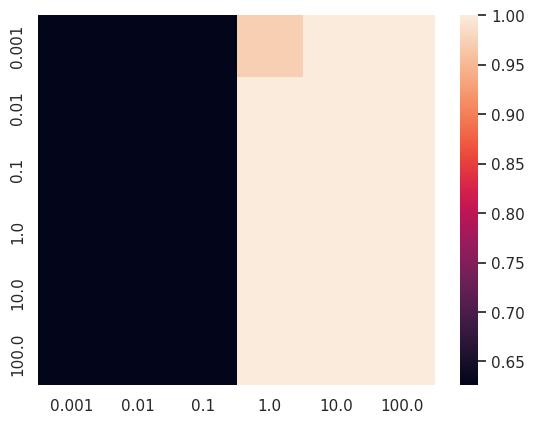

In [ ]:
# importing from skikit-learn
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, train_test_split

#loading the breast cancer dataset(classification task)
cancer = load_breast_cancer(as_frame=True)

#Renaming explanatory and target variables
x_cancer = cancer.data
y_cancer = cancer.target

# Splitting off 20% as the held_out test set
X_train_val,X_test ,y_train_val,y_test = train_test_split(x_cancer,y_cancer,test_size=0.2, stratify=y_cancer,random_state=42)

# creating an array of values to search in the hyperparameters
params_values = np.logspace(-3, 2, num=6)

#Building and validating the model for all combinations of hyperparameters
scores = {}
for gamma in params_values:
  for C in params_values:
    svm = SVC(gamma=gamma,C=C)
    svm.fit(X_train_val,y_train_val)
    scores[(gamma,C)] = svm.score(X_train_val,y_train_val)
#After finishing for the loop , convert the 'scores' dictionary to pandas series
socres = pd.Series(scores)
#Display the result
print(f'Best Score:{socres.max():.2f}')
print(f'Parameter values (gamma,c) at best score :{socres.idxmax()}')

#Display a heatmap. The vertical axis shows gamma, and the horizontal axis shows c
sns.heatmap(socres.unstack())


In [ ]:
# initializing and training the model using the best hyperparameters
model = SVC(gamma=socres.idxmax()[0],C=socres.idxmax()[1])
model.fit(X_train_val,y_train_val)

#Displaying results
print(f'SVC train score:{model.score(X_train_val,y_train_val):.2f}')
print(f'SVC test score:{model.score(X_test,y_test):.2f}')

SVC train score:1.00
SVC test score:0.88


In [ ]:
# imporiting from scikit-learn
from sklearn.metrics import confusion_matrix

#Calculating predicted values using the test data
y_pred = model.predict(X_test)

m= confusion_matrix(y_test, y_pred)
print(f'confusion matrix:\n')

confusion matrix:



In [ ]:
#Accurcy is the proportion of correct predictions out of the total predictions
accuracy = (m[0,0] + m[1,1] )/m.sum()
print(f'Accuracy:{accuracy:.3f}')

#Precision measures the proportion of the predicted postives that are actual positives
#Calculating precison
precision = (m[1,1])/m[:,1].sum()

recall = (m[1,1])/m[1,:].sum()

#F1 score is the harmonic mean of precision and recall
f1 = 2 * (precision * recall) /(precision + recall)
print(f'Precion:{precision:.3f}')
print(f'Recall:{recall:.3f}')
print(f'F1 Score:{f1:.3f}')

Accuracy:0.877
Precion:0.953
Recall:0.847
F1 Score:0.897


In [ ]:
# Import
from sklearn.linear_model import LogisticRegression

# Initialize and train the model
model = LogisticRegression(random_state=0, max_iter=10000)
model.fit(X_train_val, y_train_val)

# Calculate predicted probabilities for the test data
# `predict_proba` outputs a 2D array where axis=1 index 0 holds probabilities for the negative class, and index 1 holds probabilities for the positive class.
# `[:, 1]` is used here to extract the probabilities for the positive class.
results = pd.DataFrame(model.predict_proba(X_test), columns=cancer.target_names)

# Display the first five rows of predicted probabilities
results.head()

,malignant,benign
0,1.000000,3.368324e-11
1,0.000036,9.999641e-01
2,0.948954,5.104556e-02
3,0.395614,6.043864e-01
4,1.000000,2.013843e-09


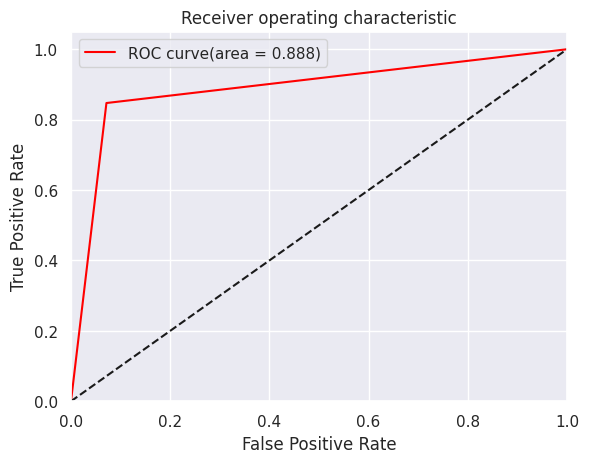

In [ ]:
# ROC_AUC curve is a very important index to measure the model perfomance .Obtained by passing FPR and TPR in that order
from sklearn.metrics import roc_curve, auc

#computing false positive rate and true postive rate
fpr, tpr, thresholds = roc_curve(y_test, y_pred)

#Calculating AUC
auc_value = auc(fpr,tpr)

#plotting the curve
plt.plot(fpr, tpr, color ='red',label='ROC curve(area = %.3f)' %auc_value)
plt.plot([0,1],[0,1],'k--')
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="best")

In [ ]:
# import the function to directly calculate ROC_AUC
from sklearn.metrics import roc_auc_score

#similar to other scoring functions, pass the observed value
roc_auc_score(y_test, y_pred)

np.float64(0.8878968253968255)